# Delta Air Lines: Flight Delay Prediction

**Applied Machine Learning - Fall 2026**

**Business question:** How can Delta Air Lines use historical flight information to anticipate arrival delays and support proactive operational decision-making?

**Machine learning question:** Using only information available before scheduled departure, how accurately can we predict whether a Delta-operated flight will arrive at least 15 minutes late, and which pre-departure flight characteristics are most predictive of delay risk?

**Scope:** U.S. BTS Reporting Carrier On-Time Performance records for 2025. We predict `ARR_DEL15` for completed flights with observed arrival outcomes. 

**Prediction timing:** Before scheduled departure. Actual departure/arrival outcomes must never be predictors.

This notebook shows every step from raw data to models: loading the data (Section 2), checking its quality (Section 3), cleaning it and making features (Section 4), and preparing it for the models (Section 5). All findings are based on the output shown below.


#LAD OS KIGGE PÅ DENNE START IGEN INDEN VI AFLEVERER, HVIS DER SKAL TILFØJES NOGET ELLER MANGLER NOGET

## 1. Import libraries and set the file paths

We load the Python libraries we need and point to the 12 monthly data files. The notebook must be run from the folder where both this notebook and the `data/` folder are placed. If a file is missing, the cell stops with an error that names the missing file.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
MONTHLY_FILES = [DATA_DIR / f"{month:02d}-2025.csv" for month in range(1, 13)]

missing_files = [str(path) for path in MONTHLY_FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing BTS monthly file(s): {missing_files}")

print(f"Found all {len(MONTHLY_FILES)} monthly files.")

Found all 12 monthly files.


## 2. Data collection

We downloaded the 2025 flight data from the U.S. Bureau of Transportation Statistics (BTS) as 12 monthly files and stacked them into one table. To keep the data small, we only read the 11 columns we need from each file, and we only keep flights operated by Delta (DL). For each month we print the total number of flights and the number of Delta flights, so it is clear how the dataset was built. At the end, we check that all 12 months are there.

This is described in Section 2.1 of the report.

In [2]:
# the 11 columns we need, grouped in 4 categories
EXPECTED_COLUMNS = [
    # Flight Information
    "FL_DATE", "OP_UNIQUE_CARRIER", "ORIGIN", "DEST",
    # Schedule
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
    # Flight Status
    "CANCELLED", "DIVERTED",
    # Outcome (target)
    "ARR_DEL15",
]

# an empty list where we save the Delta flights from each month
monthly_delta = []

# going through the 12 monthly files one by one
for file_path in MONTHLY_FILES:
    # reading only the 11 columns we need
    monthly = pd.read_csv(file_path, usecols=EXPECTED_COLUMNS)

    # keeping only flights operated by Delta (DL)
    delta = monthly[monthly["OP_UNIQUE_CARRIER"] == "DL"]

    # showing how many flights the file had, and how many were Delta
    print(file_path.name, "- all flights:", len(monthly), "- Delta flights:", len(delta))

    # saving the Delta flights in the list
    monthly_delta.append(delta)

# stacking the 12 months on top of each other into one table
df = pd.concat(monthly_delta, ignore_index=True)

# turn FL_DATE from text into a real date, so we can get the month and weekday later
df["FL_DATE"] = pd.to_datetime(df["FL_DATE"], format="%m/%d/%Y %I:%M:%S %p")

# show the total number of Delta flights in 2025
print("Total Delta flights in 2025:", len(df))

# check that we have flights from all 12 months (1 = January, 12 = December)
df["FL_DATE"].dt.month.value_counts().sort_index()

01-2025.csv - all flights: 539747 - Delta flights: 76306


02-2025.csv - all flights: 504884 - Delta flights: 71333


03-2025.csv - all flights: 600872 - Delta flights: 84487


04-2025.csv - all flights: 583950 - Delta flights: 84188


05-2025.csv - all flights: 605648 - Delta flights: 89931


06-2025.csv - all flights: 611575 - Delta flights: 91122


... (3 outputs left out)

10-2025.csv - all flights: 605844 - Delta flights: 90097


11-2025.csv - all flights: 570550 - Delta flights: 84475


12-2025.csv - all flights: 582304 - Delta flights: 85139
Total Delta flights in 2025: 1026332


FL_DATE
1     76306
2     71333
3     84487
4     84188
5     89931
6     91122
7     94066
8     90313
9     84875
10    90097
11    84475
12    85139
Name: count, dtype: int64

## 3. Getting to know the data (EDA) and data quality

**The main idea (from Session 2):** before we clean the data, we first look for problems. In this section we only **look** at the data. We do not change anything yet.

**The plan:**
1. Step 1 – How big is the data, and what type of data is in each column?
2. Step 2 (Check 1) – Does each column look normal on its own?
3. Step 3 (Check 2) – Do the columns make sense together?
4. Step 4 (Check 3) – Does the data follow the rules?
5. Step 5 (Check 4) – What is missing, and why?
6. Summary – the 7 data quality dimensions

**Step 1: How big is the data, and what type of data is in each column?**

In [3]:
# ===== EDA: size and data types =====
# show the first 5 rows, to check that the data was read in correctly
display(df.head(5))

# number of rows (flights) and columns
print("--- Size ---")
print("Rows (flights):", df.shape[0])
print("Columns:", df.shape[1])

# first and last date, number of different dates and airports
print("\n--- Dates and airports ---")
print("Date range:", df["FL_DATE"].min().date(), "to", df["FL_DATE"].max().date())
print("Unique dates:", df["FL_DATE"].nunique())
print("Unique origin airports:", df["ORIGIN"].nunique())
print("Unique destination airports:", df["DEST"].nunique())

# column names, how many cells are filled in, and the data type of each column
print("\n--- Data types ---")
df.info()

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025-01-01,DL,ABQ,ATL,635,1132,0.0,0.0,0.0,177.0,1269.0
1,2025-01-01,DL,ABQ,ATL,1135,1633,0.0,0.0,0.0,178.0,1269.0
2,2025-01-01,DL,ABQ,MSP,800,1139,0.0,0.0,0.0,159.0,981.0
3,2025-01-01,DL,ALB,ATL,605,859,0.0,0.0,0.0,174.0,853.0
4,2025-01-01,DL,ALB,ATL,1413,1705,0.0,0.0,0.0,172.0,853.0


--- Size ---
Rows (flights): 1026332
Columns: 11

--- Dates and airports ---
Date range: 2025-01-01 to 2025-12-31
Unique dates: 365
Unique origin airports: 153
Unique destination airports: 153

--- Data types ---
<class 'pandas.DataFrame'>
RangeIndex: 1026332 entries, 0 to 1026331
Data columns (total 11 columns):
 #   Column             Non-Null Count    Dtype         
---  ------             --------------    -----         
 0   FL_DATE            1026332 non-null  datetime64[us]
 1   OP_UNIQUE_CARRIER  1026332 non-null  str           
 2   ORIGIN             1026332 non-null  str           
 3   DEST               1026332 non-null  str           
 4   CRS_DEP_TIME       1026332 non-null  int64         
 5   CRS_ARR_TIME       1026332 non-null  int64         
 6   ARR_DEL15          1012427 non-null  float64       
 7   CANCELLED          1026332 non-null  float64       
 8   DIVERTED           1026332 non-null  float64       
 9   CRS_ELAPSED_TIME   1026332 non-null  float64       
 

**Findings – Step 1:**
- **Size:** 1,026,332 Delta flights and 11 columns.
- **Dates:** All 365 days of 2025 are there.
- **Airports:** Delta flies from 153 airports and to 153 airports.
- **Data types:** FL_DATE is a date, OP_UNIQUE_CARRIER, ORIGIN and DEST are text, and the rest are numbers. This is what we expect.
- **Empty cells:** Only ARR_DEL15 (the target) has empty cells. We look at this in Check 4.

**Step 2 (Check 1): Does each column look normal on its own? (Univariate analysis)**

,DISTANCE,CRS_ELAPSED_TIME
count,1026332.0,1026332.0
mean,959.0,161.0
std,653.0,80.0
min,95.0,44.0
25%,481.0,101.0
50%,761.0,139.0
75%,1276.0,202.0
max,5095.0,739.0


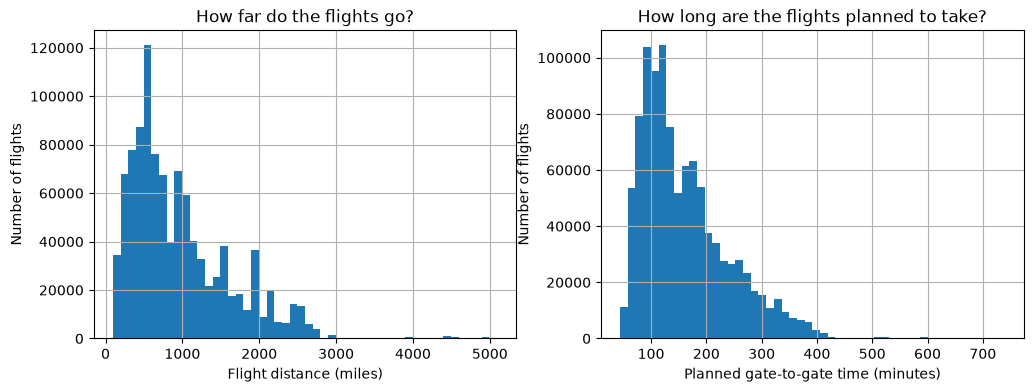

ARR_DEL15
0.0    0.802
1.0    0.198
Name: proportion, dtype: float64


In [4]:
# CRS = the airline's schedule (the plan). It is known before the flight leaves
# CRS_ELAPSED_TIME = planned time from gate to gate, taxi time included

display(df[["DISTANCE", "CRS_ELAPSED_TIME"]].describe().round(0))

# histograms of flight distance and planned gate-to-gate time, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["DISTANCE"].hist(bins=50, ax=axes[0])
axes[0].set(title="How far do the flights go?",
            xlabel="Flight distance (miles)", ylabel="Number of flights")
df["CRS_ELAPSED_TIME"].hist(bins=50, ax=axes[1])
axes[1].set(title="How long are the flights planned to take?",
            xlabel="Planned gate-to-gate time (minutes)", ylabel="Number of flights")
plt.show()

# share of on-time (0) and late (1) flights (value_counts skips empty cells by itself)
print(df["ARR_DEL15"].value_counts(normalize=True).round(3))

**Findings – Step 2:**
- **All values look realistic.** Distance goes from 95 to 5,095 miles, and the planned gate-to-gate time goes from 44 to 739 minutes. There are no zeros and no negative values.
- **Times:** CRS_DEP_TIME and CRS_ARR_TIME are stored as hhmm numbers (1430 = 14:30). This is not an error, but it is a problem for a model: 15:59 is stored as 1559 and 16:00 as 1600, so the two times look 41 apart, although only one minute has passed. We therefore turn the times into minutes after midnight (0–1439) in Section 4.
- **Target:** 80.2% of the flights are on time and **19.8% are late**. The data is **unbalanced**, so accuracy alone can be misleading: a model that always guesses "on time" would already be 80% correct. We therefore also use precision, recall and F1.

**Step 3 (Check 2): Do the columns make sense together? (Bivariate and multivariate analysis)**

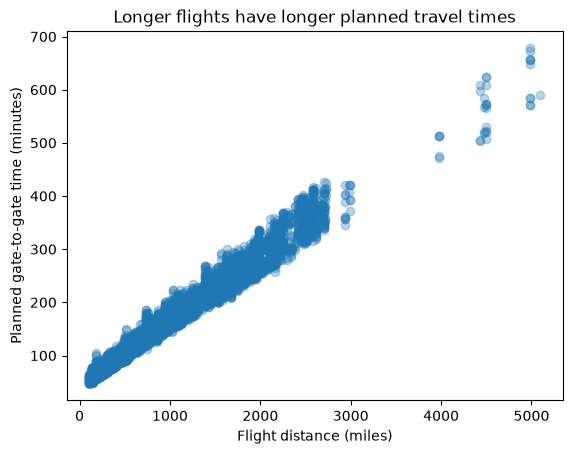

Correlation: 0.98
Strange flights: 0


In [5]:
# 10,000 random flights
sample = df.sample(10000, random_state=1)
plt.scatter(sample["DISTANCE"], sample["CRS_ELAPSED_TIME"], alpha=0.3)
plt.xlabel("Flight distance (miles)")
plt.ylabel("Planned gate-to-gate time (minutes)")
plt.title("Longer flights have longer planned travel times")
plt.show()

# correlation: 1 = perfect, 0 = no connection
print("Correlation:", round(df["DISTANCE"].corr(df["CRS_ELAPSED_TIME"]), 2))

# strange flights: over 1,500 miles but under 60 minutes (0 = none)
strange = df[(df["DISTANCE"] > 1500) & (df["CRS_ELAPSED_TIME"] < 60)]
print("Strange flights:", len(strange))

**Findings – Step 3:**
- Distance and planned gate-to-gate time fit together: the longer the distance, the longer the planned time (correlation 0.98). The two columns carry almost the same information. We come back to this when we choose features in Section 5.
- There are no strange flights, such as a long distance with a very short planned time.

**Step 4 (Check 3): Does the data follow the rules? (Constraint and rule checking)**

In [6]:
# True = all flights follow the rule, False = some flights break it
# % 100 gives the last two digits of the time (the minutes)
rules = {
    "ARR_DEL15 is only 0 or 1": df["ARR_DEL15"].dropna().isin([0, 1]).all(),
    "CANCELLED is only 0 or 1": df["CANCELLED"].isin([0, 1]).all(),
    "DIVERTED is only 0 or 1": df["DIVERTED"].isin([0, 1]).all(),
    "All flights are from 2025": (df["FL_DATE"].dt.year == 2025).all(),
    "CRS_DEP_TIME is 0-2359": df["CRS_DEP_TIME"].between(0, 2359).all(),
    "CRS_DEP_TIME minutes < 60": (df["CRS_DEP_TIME"] % 100 < 60).all(),
    "CRS_ARR_TIME is 0-2359": df["CRS_ARR_TIME"].between(0, 2359).all(),
    "CRS_ARR_TIME minutes < 60": (df["CRS_ARR_TIME"] % 100 < 60).all(),
    "DISTANCE is above 0": (df["DISTANCE"] > 0).all(),
    "CRS_ELAPSED_TIME is above 0": (df["CRS_ELAPSED_TIME"] > 0).all(),
    "ORIGIN and DEST are different": (df["ORIGIN"] != df["DEST"]).all(),
    "No duplicate rows": not df.duplicated().any(),
}

for rule, ok in rules.items():
    print(ok, "-", rule)

True - ARR_DEL15 is only 0 or 1
True - CANCELLED is only 0 or 1
True - DIVERTED is only 0 or 1
True - All flights are from 2025
True - CRS_DEP_TIME is 0-2359
True - CRS_DEP_TIME minutes < 60
True - CRS_ARR_TIME is 0-2359
True - CRS_ARR_TIME minutes < 60
True - DISTANCE is above 0
True - CRS_ELAPSED_TIME is above 0
True - ORIGIN and DEST are different
True - No duplicate rows


**Findings – Step 4:**
We made a list of rules that must always be true, for example:
- yes/no columns can only be 0 or 1
- times must be real clock times (00:00–23:59)
- distance and planned time must be above 0
- a flight cannot land at the same airport it left from
- the same flight cannot appear twice

All rules are **True**, so no flight breaks any rule. We found **no impossible values** in the data.

**A rule we did not use:** "the arrival time must be later than the departure time". This rule would be wrong for many normal flights, for two reasons:
1. **Night flights** land after midnight. For example, a flight from Salt Lake City (SLC) to Atlanta (ATL) leaves at 23:35 and arrives at 05:18.
2. **The times are local times.** A flight from Atlanta (ATL) to Los Angeles (LAX) leaves at 07:00 and lands at 08:33, although it is planned to take 273 minutes (4.5 hours), because Los Angeles is 3 hours behind Atlanta.

The real planned travel time is therefore found in CRS_ELAPSED_TIME, not by subtracting the two clock times.

**Step 5 (Check 4): What is missing, and why? (Missingness analysis)**

In [7]:
# number of empty cells in each column
print(df.isna().sum())
print()

# are the flights with an empty target cancelled or diverted?
missing = df[df["ARR_DEL15"].isna()]
print("Flights with empty target:", len(missing))
print("Of these, cancelled:", int(missing["CANCELLED"].sum()))
print("Of these, diverted:", int(missing["DIVERTED"].sum()))

# share of flights with an empty target for each month (0.03 = 3%)
print()
print("Share of empty targets per month:")
print(df["ARR_DEL15"].isna().groupby(df["FL_DATE"].dt.month).mean().round(3))

FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN                   0
DEST                     0
CRS_DEP_TIME             0
CRS_ARR_TIME             0
ARR_DEL15            13905
CANCELLED                0
DIVERTED                 0
CRS_ELAPSED_TIME         0
DISTANCE                 0
dtype: int64

Flights with empty target: 13905
Of these, cancelled: 11114
Of these, diverted: 2791

Share of empty targets per month:
FL_DATE
1     0.030
2     0.004
3     0.007
4     0.007
5     0.005
6     0.022
7     0.019
8     0.011
9     0.003
10    0.005
11    0.019
12    0.030
Name: ARR_DEL15, dtype: float64


**Findings – Step 5:**

**1. How much is missing?** Only the target ARR_DEL15 has empty cells: 13,905 flights (1.4%).

**2. Which flights are missing?** All of them were cancelled (11,114) or diverted (2,791). They are most common in January and December (3%) and rare in February and September (under 0.5%).

**3. Which type of missingness is it?** **MAR (Missing At Random).** There is a clear pattern, and we can explain it with other columns (CANCELLED, DIVERTED and the month). It is not MCAR, because it is not completely random, and it is not MNAR, because the reason is not hidden.

**4. What do we do?** We **remove** these flights in Section 4. Filling in a value makes no sense: a cancelled or diverted flight never arrived at its destination, so it has no arrival delay. Filling in the average (about 0.2) would also be wrong, because a flight cannot be "0.2 late".

**5. How could this affect our results?** Cancellations are most common in busy winter and holiday months. Removing them may make the data look slightly calmer than reality, and our model cannot predict cancellations, only delays.

**Summary – the 7 data quality dimensions**

| Dimension | What it asks | Our answer |
|---|---|---|
| Accuracy | Are the values correct? | Yes. The data comes from BTS, and all values look realistic (Check 1). |
| Completeness | Is anything missing? | Only the target, for 1.4% of the flights (Check 4). |
| Consistency | Is everything written the same way? | Yes. For example, all times are written as hhmm (Check 1). |
| Timeliness | Is the data recent enough? | Yes. 2025 is the newest full year. |
| Validity | Does the data follow the rules? | Yes. All rules are True, and there are no duplicates (Check 3). |
| Relevance | Does the data fit our question? | Yes. We only use information that is known before the flight leaves, plus the target. |
| Representativeness | Does the data show the full picture? | Mostly. We have all Delta flights in 2025, but removing cancelled and diverted flights leaves out some of the worst days. |

**Conclusion:** The data is in good shape. We found two things to handle in Section 4:
1. the missing target for cancelled and diverted flights, which we remove
2. the hhmm format of the scheduled times, which we turn into minutes after midnight

## 4. Data wrangling

**The plan:**
1. Step 1 – Remove the flights without a target
2. Step 2 – Make new features from the date and the times
3. Step 3 – Turn the airports into 0/1 columns
4. Step 4 – Check the data again

**Note on the date:** FL_DATE was already turned into a real date in Section 2, when we loaded the data. We did it there because the checks in Section 3 needed to read the date, for example to check that all flights are from 2025. This only changes the format, not the values: pandas can now read the text as a date.

**Step 1: Remove the flights without a target**

In [8]:
# keep only flights that have a target (not cancelled and not diverted)
clean = df[df["ARR_DEL15"].notna()].copy()

# the target is now only 0 or 1, so we store it as a whole number
clean["ARR_DEL15"] = clean["ARR_DEL15"].astype(int)

print("Before:", len(df), "flights")
print("After:", len(clean), "flights")
print("Removed:", len(df) - len(clean), "flights")

Before: 1026332 flights
After: 1012427 flights
Removed: 13905 flights


**Findings – Step 1:** We removed 13,905 flights. As shown in Check 4, all of them were cancelled or diverted, so they never arrived and there is no delay to predict. We now have 1,012,427 flights. We save the cleaned data in a new table called `clean`, so the original table `df` stays unchanged.

**Step 2: Make new features from the date and the times**

In [9]:
# month (1 = January, 12 = December) and weekday (1 = Monday, 7 = Sunday) from the date
clean["MONTH"] = clean["FL_DATE"].dt.month
clean["DAY_OF_WEEK"] = clean["FL_DATE"].dt.dayofweek + 1

# scheduled departure and arrival as minutes after midnight
# // 100 gives the hours and % 100 gives the minutes: 1430 -> 14 * 60 + 30 = 870
clean["DEP_MINUTES"] = (clean["CRS_DEP_TIME"] // 100) * 60 + clean["CRS_DEP_TIME"] % 100
clean["ARR_MINUTES"] = (clean["CRS_ARR_TIME"] // 100) * 60 + clean["CRS_ARR_TIME"] % 100

# show 5 flights, to check that the new columns look right
display(clean[["FL_DATE", "MONTH", "DAY_OF_WEEK", "CRS_DEP_TIME", "DEP_MINUTES", "CRS_ARR_TIME", "ARR_MINUTES"]].head())

,FL_DATE,MONTH,DAY_OF_WEEK,CRS_DEP_TIME,DEP_MINUTES,CRS_ARR_TIME,ARR_MINUTES
0,2025-01-01,1,3,635,395,1132,692
1,2025-01-01,1,3,1135,695,1633,993
2,2025-01-01,1,3,800,480,1139,699
3,2025-01-01,1,3,605,365,859,539
4,2025-01-01,1,3,1413,853,1705,1025


**Findings – Step 2:** We made four new features:
- **MONTH** and **DAY_OF_WEEK** come from the date, so the model can find seasonal and weekly patterns.
- **DEP_MINUTES** and **ARR_MINUTES** come from the scheduled departure and arrival times. As shown in Check 1, hhmm numbers are uneven: 1559 and 1600 look 41 apart, although only one minute has passed. Minutes after midnight give an even scale from 0 to 1439, where 15:59 (959) and 16:00 (960) are exactly one minute apart, and no information is lost.

**Step 3: Turn the airports into 0/1 columns**

ORIGIN and DEST are categorical attributes without a natural order. As in Lecture 4 (ocean view: No = 0, Yes = 1), we turn them into binary 0/1 attributes: one attribute per airport, with 1 if the flight uses that airport and 0 if not.

In [10]:
# one column per airport, e.g. ORIGIN_ATL = 1 if the flight leaves from Atlanta, else 0
# the result is saved in a new table, model_df, which we use for the models
# clean keeps ORIGIN and DEST as text, so we can still use them to look at the data
# dtype="int8" gives 0/1 instead of True/False, and uses little memory
model_df = pd.get_dummies(clean, columns=["ORIGIN", "DEST"], dtype="int8")

# lists of the new column names, so we can find them again later
origin_cols = [col for col in model_df.columns if col.startswith("ORIGIN_")]
dest_cols = [col for col in model_df.columns if col.startswith("DEST_")]
print("Number of ORIGIN columns:", len(origin_cols))
print("Number of DEST columns:", len(dest_cols))

# show 5 flights and a few of the new columns
display(model_df[["ORIGIN_ATL", "ORIGIN_JFK", "ORIGIN_LAX", "DEST_ATL", "DEST_JFK", "DEST_LAX"]].head())

Number of ORIGIN columns: 153
Number of DEST columns: 153


,ORIGIN_ATL,ORIGIN_JFK,ORIGIN_LAX,DEST_ATL,DEST_JFK,DEST_LAX
0,0,0,0,1,0,0
1,0,0,0,1,0,0
2,0,0,0,0,0,0
3,0,0,0,1,0,0
4,0,0,0,1,0,0


**Findings – Step 3:** Delta flies from 153 airports and to 153 airports, so we get 306 new 0/1 columns.

We save the result in a new table called `model_df`, which we use for all the models. The table `clean` keeps ORIGIN and DEST as text, so we can still use it to look at the data, for example delays per airport.

Each flight has a 1 in exactly one ORIGIN column and exactly one DEST column, and 0 in all the others (checked in Step 4).

We can do this before the train/test split, because the encoding does not learn anything from the data. It only turns each airport name into its own column, so no information leaks from the test data into the training data.

**Step 4: Check the data again**

In [11]:
# size, empty cells and the target after all the changes
print("Rows and columns in clean:", clean.shape)
print("Rows and columns in model_df:", model_df.shape)
print("Empty cells in total:", clean.isna().sum().sum())
print(clean["ARR_DEL15"].value_counts(normalize=True).round(3))

# check that the new columns only have possible values
print("MONTH is 1-12:", clean["MONTH"].between(1, 12).all())
print("DAY_OF_WEEK is 1-7:", clean["DAY_OF_WEEK"].between(1, 7).all())
print("DEP_MINUTES is 0-1439:", clean["DEP_MINUTES"].between(0, 1439).all())
print("ARR_MINUTES is 0-1439:", clean["ARR_MINUTES"].between(0, 1439).all())

# each flight leaves from exactly one airport and lands at exactly one airport,
# so the ORIGIN columns must add up to 1 in every row, and the same for the DEST columns
print("Exactly one ORIGIN airport per flight:", (model_df[origin_cols].sum(axis=1) == 1).all())
print("Exactly one DEST airport per flight:", (model_df[dest_cols].sum(axis=1) == 1).all())

# after removing the flights without a target, no flights should be cancelled or diverted
print("CANCELLED and DIVERTED are all 0:", (clean[["CANCELLED", "DIVERTED"]] == 0).all().all())

# number of flights and share of delayed flights for each departure hour (0.08 = 8%)
# // 60 groups the minutes into whole hours, only to make the table short enough to read
dep_hour = (clean["DEP_MINUTES"] // 60).rename("DEP_HOUR")
display(clean.groupby(dep_hour)["ARR_DEL15"].agg(flights="size", delay_rate="mean").round(2))

Rows and columns in clean: (1012427, 15)
Rows and columns in model_df: (1012427, 319)


Empty cells in total: 0
ARR_DEL15
0    0.802
1    0.198
Name: proportion, dtype: float64
MONTH is 1-12: True
DAY_OF_WEEK is 1-7: True
DEP_MINUTES is 0-1439: True
ARR_MINUTES is 0-1439: True
Exactly one ORIGIN airport per flight: True


Exactly one DEST airport per flight: True
CANCELLED and DIVERTED are all 0: True


,flights,delay_rate
DEP_HOUR,,
0,2155,0.14
1,505,0.17
3,16,0.25
5,25969,0.08
6,69797,0.09
7,87951,0.12
8,64760,0.13
9,53385,0.15
10,56201,0.16


**Findings – Step 4:**
- **Size:** We have 1,012,427 flights. `clean` has 15 columns: the 11 original columns plus the 4 new time features. `model_df` has 319 columns: the same 15 columns, minus ORIGIN and DEST, plus the 306 airport columns.
- **No empty cells:** Removing the flights without a target worked, so no values are missing.
- **Target:** 80.2% of the flights are on time and 19.8% are late. This is the same as before, so removing the cancelled and diverted flights did not change the balance.
- **New features:** All new columns only contain possible values, and every flight has exactly one ORIGIN airport and one DEST airport (all True).
- **Delays by hour:** The share of late flights rises during the day, from 8% at 5 am to 31% at 7 pm, and then drops to 22% late in the evening. This shows that the departure time is a useful feature. Hours 2 and 4 are missing because Delta has no departures at those times.
- **Columns we do not use as features:** Some columns stay in the tables but are not given to the models. FL_DATE is replaced by MONTH and DAY_OF_WEEK, and CRS_DEP_TIME and CRS_ARR_TIME are replaced by DEP_MINUTES and ARR_MINUTES. OP_UNIQUE_CARRIER is always DL, and CANCELLED and DIVERTED are always 0 after cleaning, so they carry no information. We remove them in Section 5.

## 5. Preparing the data for the models

Before we can train models, the data must be split into the parts the models need.

**The plan:**
1. Step 1 – Split the table into features (X) and target (y)
2. Step 2 – Split the flights into a training set and a test set
3. Step 3 – Scale the numeric features (only for the models that need it)

**Step 1: Split the table into features (X) and target (y)**

In [12]:
# y = what we want to predict: 1 = the flight arrived at least 15 minutes late, 0 = on time
y = model_df["ARR_DEL15"]

# X = the information the model may use to predict y
# we remove the target and the columns that are not features (see Findings - Step 4 in Section 4)
NOT_FEATURES = [
    "ARR_DEL15",                     # the target itself
    "FL_DATE",                       # replaced by MONTH and DAY_OF_WEEK
    "CRS_DEP_TIME", "CRS_ARR_TIME",  # replaced by DEP_MINUTES and ARR_MINUTES
    "OP_UNIQUE_CARRIER",             # always DL
    "CANCELLED", "DIVERTED",         # always 0 after cleaning
]
X = model_df.drop(columns=NOT_FEATURES)

# the numeric features (all the others are the 0/1 airport columns)
NUMERIC_FEATURES = ["MONTH", "DAY_OF_WEEK", "DEP_MINUTES", "ARR_MINUTES", "CRS_ELAPSED_TIME", "DISTANCE"]

print("X:", X.shape[0], "flights and", X.shape[1], "features")
print("  numeric features:", len(NUMERIC_FEATURES))
print("  airport features:", len(origin_cols) + len(dest_cols))
print("y:", y.shape[0], "flights")

# check that X has no text or date columns left (a model can only use numbers)
print("All features are numbers:", X.dtypes.apply(pd.api.types.is_numeric_dtype).all())

X: 1012427 flights and 312 features
  numeric features: 6
  airport features: 306
y: 1012427 flights
All features are numbers: True


**Findings – Step 1:** X has 312 features: 6 numeric features (MONTH, DAY_OF_WEEK, DEP_MINUTES, ARR_MINUTES, CRS_ELAPSED_TIME and DISTANCE) and 306 airport columns. All of them are numbers, and all of them are known before the flight leaves, so the model does not "cheat" by using information from after departure.

**Note on DISTANCE and CRS_ELAPSED_TIME:** As shown in Check 2, these two features are almost the same (correlation 0.98). For tree-based models this is not a problem. For linear models, such as logistic regression, it can make the coefficients harder to interpret, so there it can make sense to use only one of them.

**Step 2: Split the flights into a training set and a test set**

In [13]:
from sklearn.model_selection import train_test_split

# 80% of the flights are used to train the models, 20% are kept aside to test them
# stratify=y: the share of late flights (about 20%) is the same in both parts
# random_state=1: the split is the same every time we run the notebook
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=1
)

print("Training set:", len(X_train), "flights")
print("Test set:", len(X_test), "flights")

# share of late flights in each part (should be the same, about 0.198)
print("Share of late flights in training set:", round(y_train.mean(), 3))
print("Share of late flights in test set:", round(y_test.mean(), 3))

Training set: 809941 flights
Test set: 202486 flights
Share of late flights in training set: 0.198
Share of late flights in test set: 0.198


**Findings – Step 2:** We split the flights randomly into a training set (80%) and a test set (20%). The models only learn from the training set. The test set is kept aside until the end, so we can see how well the models work on flights they have never seen.

Because the data is unbalanced, we used `stratify=y`. The share of late flights is therefore the same (19.8%) in both parts.

**A limitation to keep in mind:** Because the split is random, flights from the same day end up in both the training set and the test set. Flights on the same day share the same weather, so the model may have "seen" a bad weather day during training. This can make the test results look a little better than they would be on a completely new period. A stricter alternative would be to train on the first months of the year and test on the last months.

**Step 3: Scale the numeric features (only for the models that need it)**

In [14]:
from sklearn.preprocessing import StandardScaler

# the numeric features have very different scales, e.g. DAY_OF_WEEK goes from 1 to 7
# and DISTANCE goes up to 5,095. Scaling gives them all mean 0 and standard deviation 1.
# the 0/1 airport columns are not scaled, they are already on a small scale.
scaler = StandardScaler()

# fit the scaler on the training set ONLY, so it learns nothing from the test set
scaler.fit(X_train[NUMERIC_FEATURES])

# use the same scaler on both sets (copies, so X_train and X_test stay unscaled)
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[NUMERIC_FEATURES] = scaler.transform(X_train[NUMERIC_FEATURES])
X_test_scaled[NUMERIC_FEATURES] = scaler.transform(X_test[NUMERIC_FEATURES])

# check: in the training set the numeric features now have mean 0 and standard deviation 1
display(X_train_scaled[NUMERIC_FEATURES].describe().loc[["mean", "std"]].round(2))

,MONTH,DAY_OF_WEEK,DEP_MINUTES,ARR_MINUTES,CRS_ELAPSED_TIME,DISTANCE
mean,-0.0,0.0,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


**Findings – Step 3:** After scaling, the numeric features in the training set have mean 0 and standard deviation 1. In the test set they are close to, but not exactly, 0 and 1. This is expected, because the scaler only learned from the training set.

**Why we fit the scaler on the training set only:** If the scaler also learned from the test set, information from the test set would leak into the training, and the test results would look better than they really are.

**Which version to use for which model:**
- **Scaled data** (`X_train_scaled`, `X_test_scaled`): models that compare distances or use coefficients, for example KNN, logistic regression and SVM. Without scaling, a feature with large numbers (like DISTANCE) would count much more than a feature with small numbers (like DAY_OF_WEEK).
- **Unscaled data** (`X_train`, `X_test`): tree-based models, for example decision trees and random forests. They split on one feature at a time, so the scale does not matter.

**Summary – ready for modelling**

| Name | What it is |
|---|---|
| `X_train`, `y_train` | Training set: 809,941 flights, 312 features (unscaled) |
| `X_test`, `y_test` | Test set: 202,486 flights, 312 features (unscaled) |
| `X_train_scaled`, `X_test_scaled` | The same sets with the 6 numeric features scaled |

**Note on size:** The training set has about 810,000 flights and 312 features. Some models, such as KNN and SVM, become very slow on this much data. For those models we can train on a random sample of the training set.